# PRCL-0019 · FicZon Inc. Sales Effectiveness & Lead Quality Prediction

*DataMites™ capstone project PR-0019, based on a real-world business case.*

**Project goals:** (1) data exploration insights on sales effectiveness, (2) an ML model to predict the lead category (High / Low potential).

**Business problem.** FicZon sells IT products and services. Leads come in from the website, live chat, calls,
referrals and campaigns, and sales agents classify them by hand after talking to the prospect. Sales effectiveness
has dropped as the market got more competitive, so FicZon wants to **score lead quality automatically as soon as a lead
arrives**. Agents can then spend their time on the leads most likely to convert.

**Task.** Predict whether a lead is a **High potential** or **Low potential** lead from the information available when
the lead is created.

**Contents**
1. Load and inspect the data
2. Define the target (High vs Low potential)
3. Cleaning
4. Exploratory data analysis
5. Feature engineering
6. Model comparison (stratified 5-fold CV)
7. Class imbalance handling
8. Hyper-parameter tuning and decision threshold
9. Test-set evaluation
10. Feature importance
11. Robustness check: time-based hold-out
12. Save the model
13. Findings, recommendations and challenges

> **Data privacy.** The dataset comes from the institute and is not redistributed. Mobile numbers and e-mails are already masked in the export, and this notebook
> only turns them into flags (number given? e-mail provider?). Raw rows are never printed. Only aggregates and the
> trained model leave the notebook.

In [1]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from ficzon.features import (clean_raw, make_features, HIGH_STATUSES, LOW_STATUSES, LEAD_FIELDS,
                             CATEGORICAL, NUMERIC, SOURCE_CHOICES, LOCATION_CHOICES, EMAIL_CHOICES,
                             DELIVERY_CHOICES)

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate, cross_val_predict,
                                     RandomizedSearchCV)
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, precision_score, recall_score,
                             confusion_matrix, classification_report, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
SEED = 42
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
HIGH_C, LOW_C = "#2a9d8f", "#e76f51"

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=120)

## 1. Load and inspect the data

The file is read in chunks of 2,000 rows. That works on small machines too and shows how a bigger CRM export would be
handled.

In [2]:
DATA = ROOT / "Data" / "sales_data.csv"
chunks = pd.read_csv(DATA, chunksize=2000)
raw = pd.concat(chunks, ignore_index=True)
print("shape:", raw.shape)
info = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                     "missing": raw.isna().sum(),
                     "missing_%": (raw.isna().mean() * 100).round(2),
                     "unique": raw.nunique()})
info

shape: (7422, 9)


,dtype,missing,missing_%,unique
Created,object,0,0.00,6752
Product_ID,float64,58,0.78,29
Source,object,17,0.23,25
Mobile,object,1810,24.39,486
EMAIL,object,0,0.00,883
Sales_Agent,object,23,0.31,12
Location,object,58,0.78,17
Delivery_Mode,object,0,0.00,5
Status,object,0,0.00,11


In [3]:
# Odd placeholder values that are not NaN but mean 'missing'
print("EMAIL == '#VALUE!' :", (raw["EMAIL"] == "#VALUE!").sum())
print("Mobile pattern (digits -> 9), top 6:")
print(raw["Mobile"].str.replace(r"\d", "9", regex=True).value_counts(dropna=False).head(6))
print("\nCreated range:", pd.to_datetime(raw["Created"], format="%d-%m-%Y %H:%M").agg(["min", "max"]).tolist())
print("Exact duplicate rows:", raw.duplicated().sum())

EMAIL == '#VALUE!' : 1701
Mobile pattern (digits -> 9), top 6:
Mobile
999XXXXXXX    5240
NaN           1810
XXXXXXX        222
+99XXXXXXX      54
(99XXXXXXX      26
99-XXXXXXX      17
Name: count, dtype: int64

Created range: [Timestamp('2018-04-28 07:54:00'), Timestamp('2018-11-14 10:05:00')]
Exact duplicate rows: 2


In [4]:
raw["Status"].value_counts().to_frame("leads")

,leads
Status,
Junk Lead,1536
Not Responding,1129
CONVERTED,834
Just Enquiry,760
Potential,708
Long Term,646
In Progress Positive,643
In Progress Negative,626
LOST,440


## 2. Target definition: High vs Low potential

`Status` has 11 values (10 plus a lower-case duplicate, `converted`). This is the standard FicZon grouping, based on
what each status says about the prospect's intent:

| Class | Statuses | Reasoning |
|---|---|---|
| **High potential (1)** | CONVERTED, converted, In Progress Positive, Potential, Long Term, Open | Converted, or still engaged / positive / not yet worked (Open) |
| **Low potential (0)** | Junk Lead, Not Responding, Just Enquiry, In Progress Negative, LOST | Junk, unreachable, only enquiring, negative or lost |

`Open` leads have not been worked yet. They are grouped with High because in practice an open lead is still a live
opportunity. There are only 82 of them (1.1%), so the choice barely changes the results.

target
Low     4491
High    2931
Name: count, dtype: int64 
High share: 39.5%


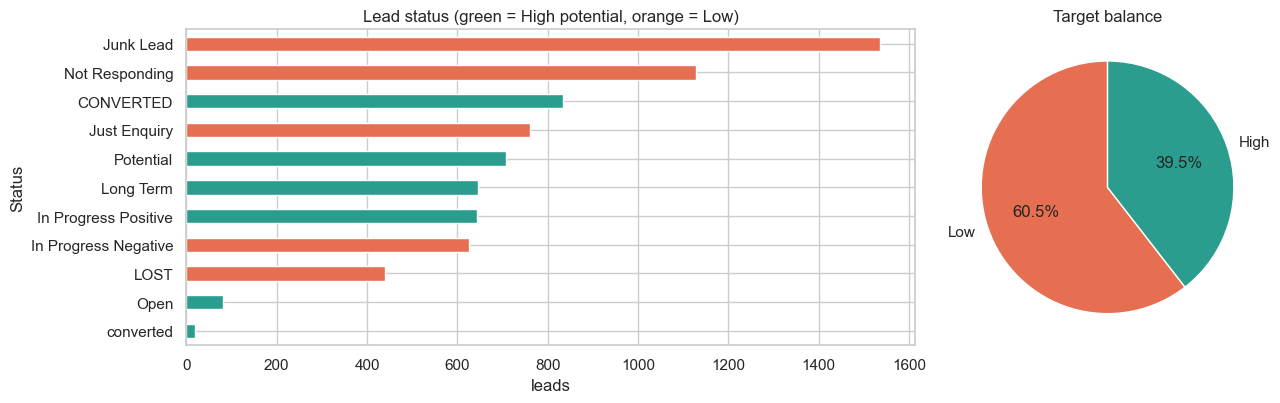

In [5]:
leads = clean_raw(raw)          # raw -> tidy, PII-free lead rows (see src/ficzon/features.py)
y_all = leads["target"]
print(y_all.value_counts().rename({1: "High", 0: "Low"}), "\nHigh share: %.1f%%" % (100 * y_all.mean()))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.3, 1]})
order = raw["Status"].value_counts().index
cols = [HIGH_C if s in HIGH_STATUSES else LOW_C for s in order]
raw["Status"].value_counts().plot.barh(ax=ax[0], color=cols)
ax[0].invert_yaxis(); ax[0].set_title("Lead status (green = High potential, orange = Low)"); ax[0].set_xlabel("leads")
y_all.map({1: "High", 0: "Low"}).value_counts().plot.pie(ax=ax[1], autopct="%1.1f%%", colors=[LOW_C, HIGH_C],
                                                         startangle=90, ylabel="")
ax[1].set_title("Target balance")
plt.tight_layout(); save(fig, "target_distribution"); plt.show()

## 3. Cleaning

`clean_raw()` in `src/ficzon/features.py` does all of the cleaning. The same code runs in the API, so training and
serving always match.

| Column | Issue found | Fix |
|---|---|---|
| `Created` | text `dd-mm-yyyy HH:MM` | parsed to datetime; used for hour / weekday features |
| `Product_ID` | 58 missing, 29 ids, many rare | `Unknown`; rare ids grouped by the encoder (min frequency 20) |
| `Source` | 25 values, near-duplicates (`Existing Client`/`Existing Customer`), 17 missing | grouped into 11 channel groups + `Unknown` |
| `Sales_Agent` | 23 missing | `Unknown` |
| `Location` | 58 missing, `Howrah` (1 lead), 7 small foreign markets | Howrah→Kolkata, foreign→`International`, `Unknown` |
| `Mobile` | masked, 1,810 missing, short/odd formats | **only** a flag `has_mobile` (≥10 digits given) |
| `EMAIL` | masked, 1,701 are the Excel error `#VALUE!` | **only** the provider: gmail / yahoo / microsoft / other / missing |
| `Status` | `CONVERTED` vs `converted` | both mapped to High |

The masked phone numbers and e-mails are personal data with no predictive content of their own, so they never get
past this step.

In [6]:
print("Missing values after cleaning:", leads[LEAD_FIELDS].isna().sum().sum())
for c in ["source", "location", "email_type"]:
    print(f"\n{c}:", leads[c].value_counts().to_dict())
print("\nhas_mobile share: %.1f%%" % (100 * leads["has_mobile"].mean()))

Missing values after cleaning: 0

source: {'Call': 2547, 'Live Chat-Direct': 1834, 'Website': 1594, 'Live Chat-Search/Ads': 601, 'Referral': 262, 'Live Chat-Content': 241, 'US Website': 137, 'Existing Client': 73, 'Campaign': 57, 'Just Dial': 57, 'Unknown': 17, 'Other': 2}

location: {'Other Locations': 2500, 'Bangalore': 2084, 'Chennai': 909, 'Hyderabad': 528, 'Delhi': 471, 'Mumbai': 402, 'International': 214, 'Pune': 142, 'Unknown': 58, 'Trivandrum': 58, 'Kolkata': 56}

email_type: {'gmail': 4256, 'missing': 1701, 'other': 751, 'yahoo': 549, 'microsoft': 165}

has_mobile share: 70.6%


## 4. Exploratory data analysis

Each chart shows the **High-potential rate** per group. The dashed line is the overall rate (39.5%), and the bar
labels give lead counts.

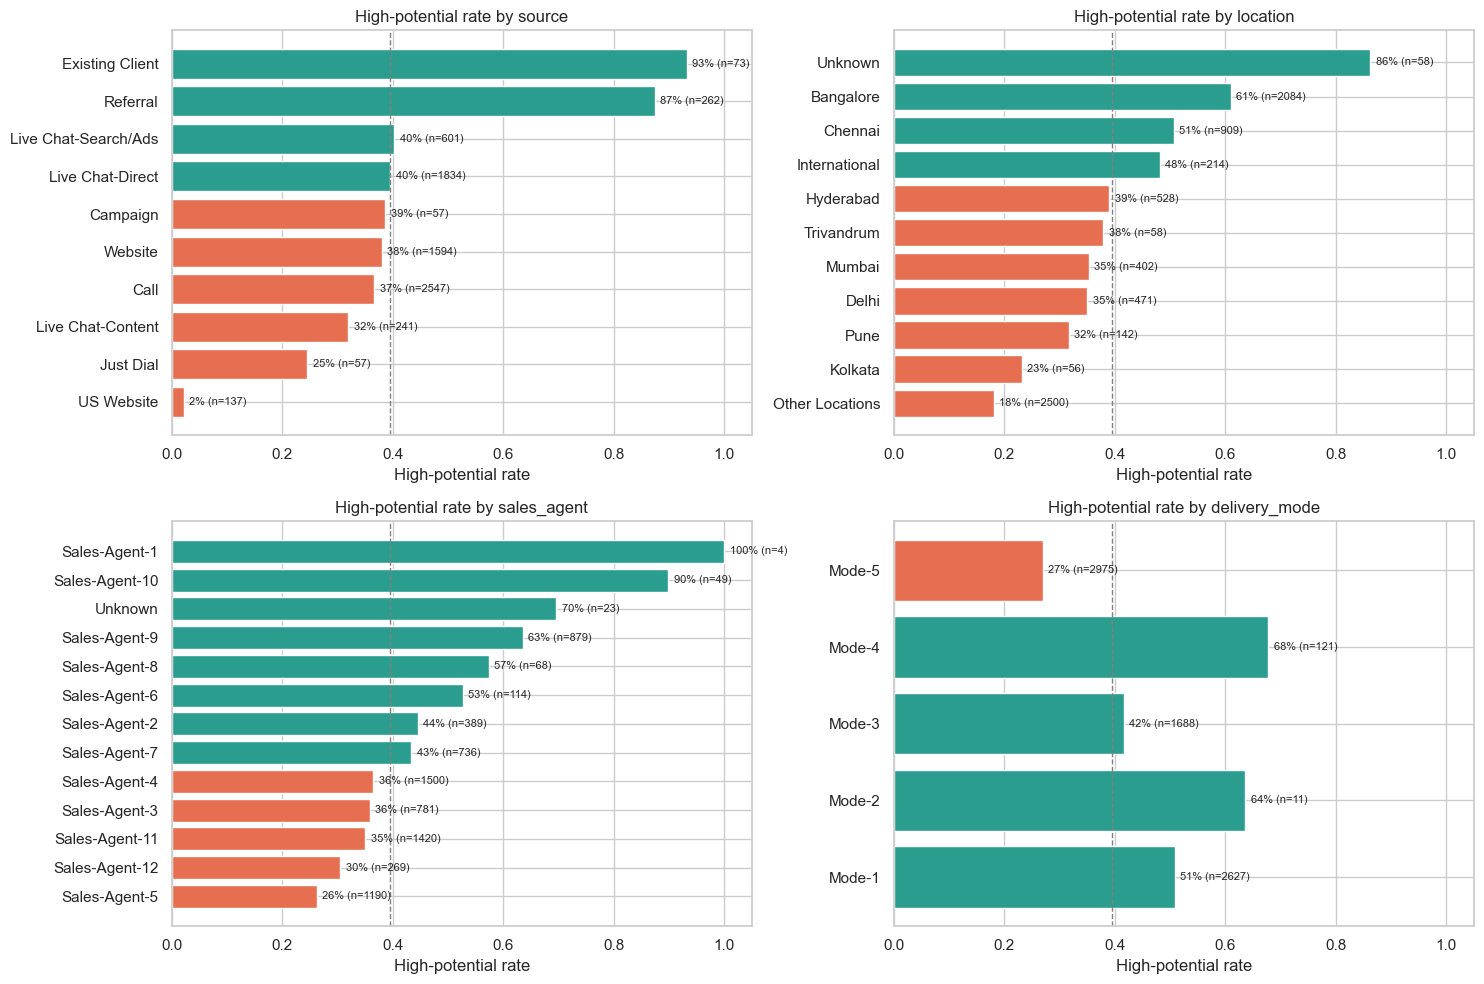

In [7]:
BASE = y_all.mean()

def rate_plot(col, ax, data=leads, top=None, min_n=20, title=None, sort=True):
    g = data.groupby(col)["target"].agg(rate="mean", n="size")
    g = g[g["n"] >= min_n]
    if sort: g = g.sort_values("rate")
    if top: g = g.tail(top)
    colors = [HIGH_C if r > BASE else LOW_C for r in g["rate"]]
    ax.barh(g.index.astype(str), g["rate"], color=colors)
    ax.axvline(BASE, ls="--", c="grey", lw=1)
    for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(r + 0.01, i, f"{r:.0%} (n={n})", va="center", fontsize=8)
    ax.set_xlim(0, 1.05); ax.set_title(title or f"High-potential rate by {col}"); ax.set_xlabel("High-potential rate")
    return g

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
rate_plot("source", axes[0, 0])
rate_plot("location", axes[0, 1])
rate_plot("sales_agent", axes[1, 0], min_n=1)
rate_plot("delivery_mode", axes[1, 1], min_n=1, sort=False)
plt.tight_layout(); save(fig, "eda_rates_by_category"); plt.show()

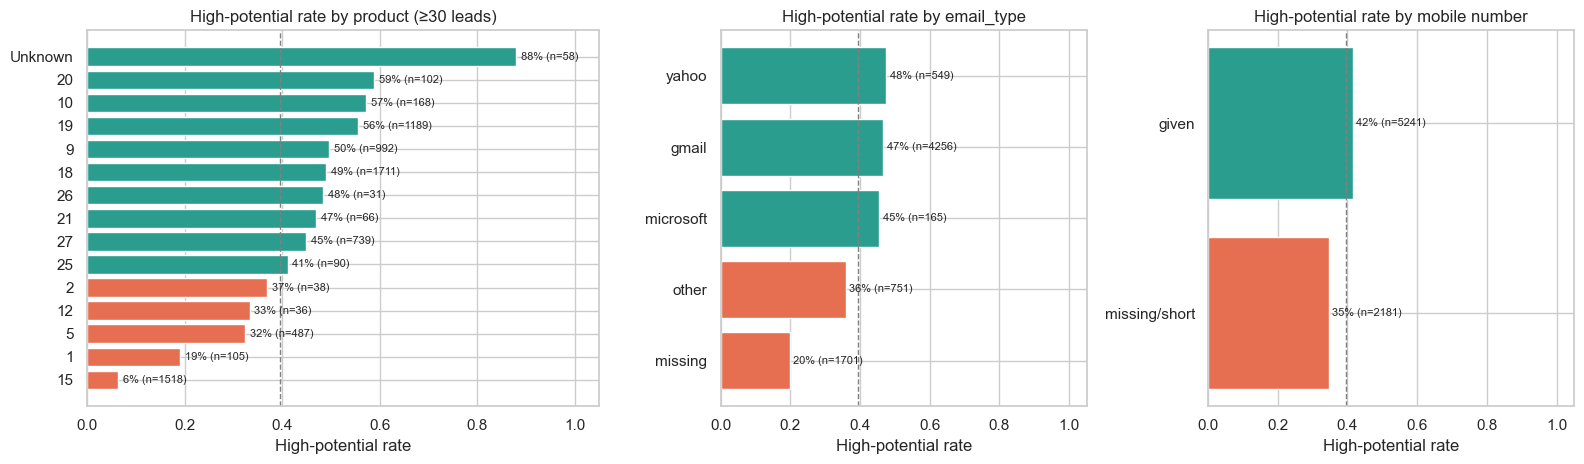

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.4, 1, 1]})
rate_plot("product_id", axes[0], min_n=30, title="High-potential rate by product (≥30 leads)")
rate_plot("email_type", axes[1], min_n=1)
leads.assign(mobile=leads["has_mobile"].map({1: "given", 0: "missing/short"})).pipe(
    lambda d: rate_plot("mobile", axes[2], data=d, min_n=1, title="High-potential rate by mobile number"))
plt.tight_layout(); save(fig, "eda_rates_product_contact"); plt.show()

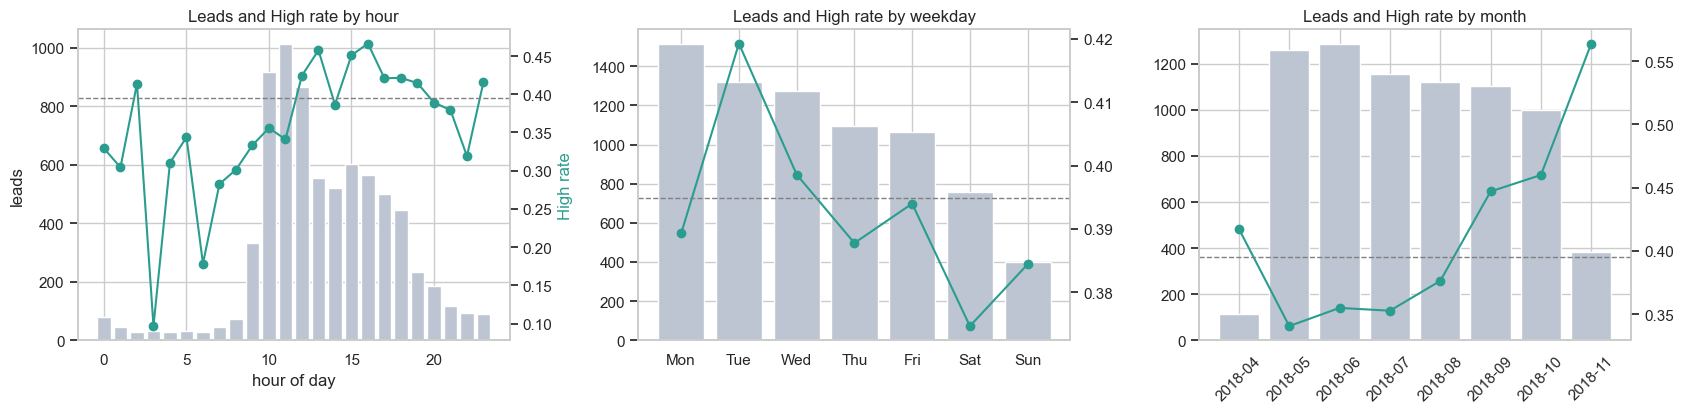

In [9]:
t = leads.assign(hour=leads["created"].dt.hour, weekday=leads["created"].dt.day_name(),
                 month=leads["created"].dt.to_period("M").astype(str))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
h = t.groupby("hour")["target"].agg(["mean", "size"])
axes[0].bar(h.index, h["size"], color="#bcc5d1"); axes[0].set_ylabel("leads"); axes[0].set_xlabel("hour of day")
a2 = axes[0].twinx(); a2.plot(h.index, h["mean"], "o-", c=HIGH_C); a2.set_ylabel("High rate", color=HIGH_C)
a2.axhline(BASE, ls="--", c="grey", lw=1); a2.grid(False); axes[0].set_title("Leads and High rate by hour")
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
d = t.groupby("weekday")["target"].agg(["mean", "size"]).reindex(days)
axes[1].bar(range(7), d["size"], color="#bcc5d1"); axes[1].set_xticks(range(7), [x[:3] for x in days])
a3 = axes[1].twinx(); a3.plot(range(7), d["mean"], "o-", c=HIGH_C); a3.axhline(BASE, ls="--", c="grey", lw=1)
a3.grid(False); axes[1].set_title("Leads and High rate by weekday")
m = t.groupby("month")["target"].agg(["mean", "size"])
axes[2].bar(m.index, m["size"], color="#bcc5d1"); axes[2].tick_params(axis="x", rotation=45)
a4 = axes[2].twinx(); a4.plot(m.index, m["mean"], "o-", c=HIGH_C); a4.axhline(BASE, ls="--", c="grey", lw=1)
a4.grid(False); axes[2].set_title("Leads and High rate by month")
plt.tight_layout(); save(fig, "eda_time"); plt.show()

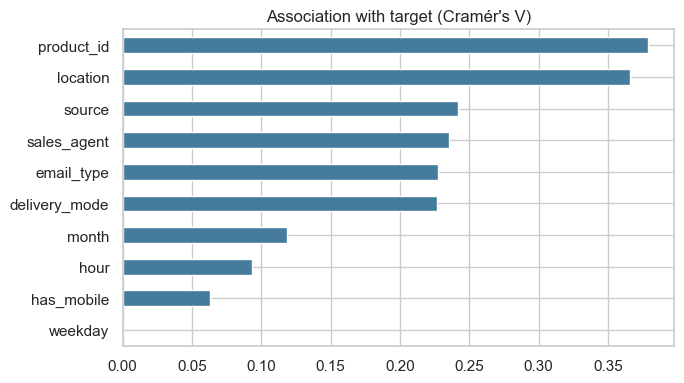

,product_id,location,source,sales_agent,email_type,delivery_mode,month,hour,has_mobile,weekday
cramers_v,0.379,0.366,0.242,0.235,0.228,0.227,0.118,0.093,0.063,0.0


In [10]:
# Association of each feature with the target (Cramér's V, bias-corrected)
from scipy.stats import chi2_contingency
def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2 = chi2_contingency(ct, correction=False)[0]; n = ct.values.sum()
    r, k = ct.shape; phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-9, min(kc - 1, rc - 1)))
assoc = pd.Series({c: cramers_v(t[c], t["target"]) for c in
                   ["delivery_mode", "sales_agent", "product_id", "source", "email_type", "location",
                    "has_mobile", "hour", "weekday", "month"]}).sort_values()
fig, ax = plt.subplots(figsize=(7, 4)); assoc.plot.barh(ax=ax, color="#457b9d")
ax.set_title("Association with target (Cramér's V)"); plt.tight_layout(); save(fig, "eda_association"); plt.show()
assoc.sort_values(ascending=False).round(3).to_frame("cramers_v").T

**EDA takeaways**
- **Product** is the strongest single signal (Cramér's V 0.38). Product 15 is the 2nd-largest product (1,518 leads),
  yet only **6.5%** of its leads are High. Products 19, 10 and 20 run at 55–59%.
- **Location** comes next (0.37): Bangalore **61%** and Chennai 51% High vs **18%** for the 2,500 "Other Locations" leads.
- **Channel**: referrals (87%) and existing clients (93%) are by far the best sources. The US website is almost all
  Low (2%). Call, website and live chat sit near the average.
- **Sales agent** matters (Agent-9 63% High vs Agent-5 26%). This reflects both who gets which leads and how each
  agent works their leads, so FicZon should treat it as a coaching signal, not only a predictor.
- **Delivery mode**: Mode-5 leads are High only 27% of the time, Mode-4 68%.
- **Contact quality**: leads with no usable e-mail (`#VALUE!`) are only 20% High vs ~47% for gmail/yahoo.
- The 58 leads with **no product and no location** are nearly all recent `Open` leads (86–88% "High"). This is an
  artefact of how open leads are recorded, so the model sees them only as an `Unknown` category.
- **Time**: hour and weekday matter only a little (weekday V ≈ 0). The monthly High rate rises from 34% to 56%, but that partly
  reflects recent leads that have not been closed out yet. **Month is therefore left out of the model**, since it
  would not carry over to future leads (see §11).

## 5. Feature engineering

`make_features()` is the first step of the saved pipeline. It turns tidy lead fields into model features:

- `time_of_day` (night / morning / afternoon / evening / late evening), `day_of_week`, `is_weekend`
- `hour_sin`, `hour_cos`: cyclic hour, so 23:00 and 00:00 count as close together
- categorical fields: one-hot encoded; categories with fewer than 20 leads go to an *infrequent* bucket, and values
  never seen before are handled safely at prediction time
- `has_mobile`, `email_type`: contact-quality flags (no PII)

In [11]:
X_all = leads[LEAD_FIELDS]
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
print("train", X_train.shape, "High %.3f" % y_train.mean(), "| test", X_test.shape, "High %.3f" % y_test.mean())

def make_pre():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                                    sparse_output=False), CATEGORICAL)],
                             remainder="passthrough", verbose_feature_names_out=False)

def make_pipe(model, sampler=None):
    steps = [("features", FunctionTransformer(make_features)), ("pre", make_pre())]
    if sampler is not None:
        return ImbPipeline(steps + [("sampler", sampler), ("model", model)])
    return Pipeline(steps + [("model", model)])

fe = make_pipe(DummyClassifier())[:-1].fit(X_train)
print("Features after encoding:", len(fe.named_steps["pre"].get_feature_names_out()))
make_features(X_train).describe(include="all").T[["count", "unique", "top", "mean"]].head(12)

train (5937, 8) High 0.395 | test (1485, 8) High 0.395
Features after encoding: 78


,count,unique,top,mean
product_id,5937,30,18,NaN
source,5937,12,Call,NaN
sales_agent,5937,13,Sales-Agent-4,NaN
location,5937,11,Other Locations,NaN
delivery_mode,5937,5,Mode-5,NaN
email_type,5937,5,gmail,NaN
time_of_day,5937,5,afternoon,NaN
day_of_week,5937,7,Monday,NaN
has_mobile,5937.0,NaN,NaN,0.703891
is_weekend,5937.0,NaN,NaN,0.15715


## 6. Model comparison: stratified 5-fold CV on the training set

Every model gets the same features and folds. The classes are 60/40, so **class weights** are switched on wherever a
model supports them (`scale_pos_weight` for XGBoost). Plain accuracy would favour the majority class, so the main
ranking metric is **ROC-AUC**, with F1 for the High class next to it.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
spw = (y_train == 0).sum() / (y_train == 1).sum()
candidates = {
    "Dummy (majority)":    DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5),
    "KNN (k=25)":          KNeighborsClassifier(n_neighbors=25),
    "Decision Tree":       DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced",
                                                  random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced",
                                                  n_jobs=-1, random_state=SEED),
    "Extra Trees":         ExtraTreesClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced",
                                                n_jobs=-1, random_state=SEED),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED),
    "XGBoost":             XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                         colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="logloss",
                                         n_jobs=-1, random_state=SEED),
    "LightGBM":            LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, subsample=0.8,
                                          subsample_freq=1, colsample_bytree=0.8, class_weight="balanced",
                                          verbose=-1, random_state=SEED),
}
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
rows = []
for name, model in candidates.items():
    t0 = time.time()
    r = cross_validate(make_pipe(model), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name, **{m: r[f"test_{m}"].mean() for m in scoring},
                 "roc_auc_std": r["test_roc_auc"].std(), "fit_s": round(time.time() - t0, 1)})
cv_results = pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)
cv_results.round(3)

,accuracy,precision,recall,f1,roc_auc,roc_auc_std,fit_s
model,,,,,,,
Gradient Boosting,0.729,0.687,0.578,0.627,0.802,0.011,5.9
XGBoost,0.712,0.616,0.720,0.664,0.800,0.013,1.5
LightGBM,0.711,0.615,0.716,0.662,0.800,0.012,1.1
Logistic Regression,0.708,0.606,0.742,0.667,0.797,0.012,0.6
Extra Trees,0.706,0.610,0.712,0.657,0.793,0.010,3.6
Random Forest,0.711,0.624,0.673,0.648,0.792,0.010,4.2
Decision Tree,0.690,0.608,0.629,0.615,0.761,0.013,0.6
KNN (k=25),0.700,0.644,0.541,0.587,0.761,0.013,2.5
Dummy (majority),0.605,0.000,0.000,0.000,0.500,0.000,0.5


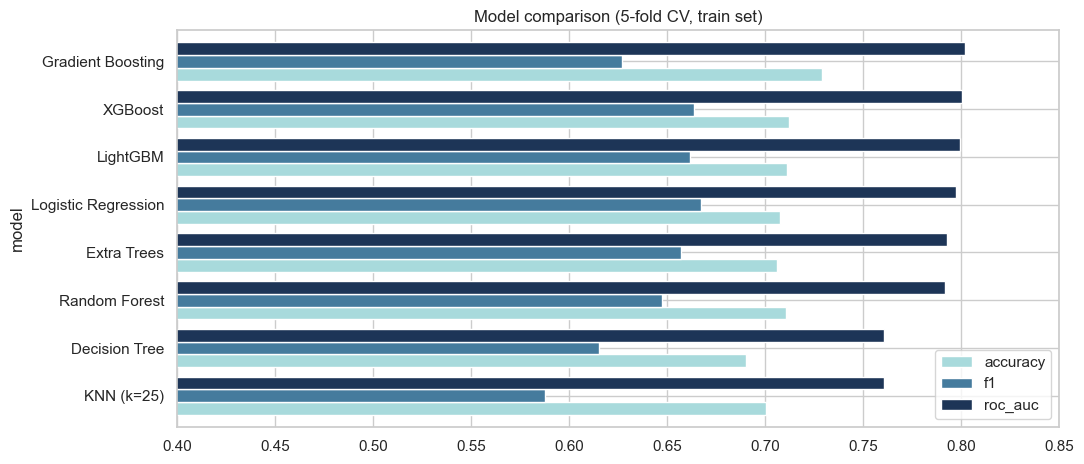

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.8))
plot_df = cv_results.drop(index="Dummy (majority)")[["accuracy", "f1", "roc_auc"]].sort_values("roc_auc")
plot_df.plot.barh(ax=ax, color=["#a8dadc", "#457b9d", "#1d3557"], width=0.8)
ax.set_xlim(0.4, 0.85); ax.set_title("Model comparison (5-fold CV, train set)"); ax.legend(loc="lower right")
plt.tight_layout(); save(fig, "model_comparison"); plt.show()

## 7. Class imbalance handling

The imbalance is moderate (60/40). The top three models are compared under four strategies: no handling, class
weights, SMOTE oversampling and random undersampling. SMOTE and undersampling run **inside** each CV fold through
an imblearn pipeline, so no synthetic rows leak into the validation folds.

In [14]:
top3 = cv_results.drop(index="Dummy (majority)").index[:3].tolist()
def variant(name, mode):
    m = clone(candidates[name])
    if mode == "none":
        if "class_weight" in m.get_params(): m.set_params(class_weight=None)
        if "scale_pos_weight" in m.get_params(): m.set_params(scale_pos_weight=1)
    return m
rows = []
for name in top3:
    for mode, sampler in [("none", None), ("class_weight", None),
                          ("SMOTE", SMOTE(random_state=SEED)), ("undersample", RandomUnderSampler(random_state=SEED))]:
        model = variant(name, "none" if mode in ("none", "SMOTE", "undersample") else "cw")
        r = cross_validate(make_pipe(model, sampler), X_train, y_train, cv=cv, scoring=scoring)
        rows.append({"model": name, "strategy": mode, **{k: r[f"test_{k}"].mean() for k in scoring}})
imb = pd.DataFrame(rows)
imb.pivot(index="model", columns="strategy", values=["f1", "roc_auc", "recall"]).round(3)

f1                                 roc_auc               \
strategy           SMOTE class_weight   none undersample   SMOTE class_weight   
model                                                                           
Gradient Boosting  0.645        0.627  0.627       0.666   0.802        0.802   
LightGBM           0.638        0.662  0.625       0.660   0.801        0.800   
XGBoost            0.638        0.664  0.629       0.667   0.803        0.800   

                                     recall                                  
strategy            none undersample  SMOTE class_weight   none undersample  
model                                                                        
Gradient Boosting  0.802       0.797  0.629        0.578  0.578       0.739  
LightGBM           0.798       0.795  0.610        0.716  0.577       0.725  
XGBoost            0.802       0.800  0.613        0.720  0.579       0.735

Class weights / resampling barely move ROC-AUC, which measures ranking and is not affected by re-weighting. They
**do** raise recall and F1 for the High class compared with no handling. Class weighting gives that gain without
making synthetic leads, so the final model uses **class weights** and then tunes the decision threshold (§8).

## 8. Hyper-parameter tuning and decision threshold

The top CV models are tuned with `RandomizedSearchCV` (ROC-AUC, same 5 folds). The model with the best tuned CV score
wins. Its probability threshold is then picked to **maximise macro-F1 on out-of-fold predictions** from the training
set, so the test set is never used for any decision. Macro-F1 weighs both errors: missing a good lead, and wasting an
agent's call on a junk lead. Maximising F1 for the High class alone pushes the threshold so low that most leads get
flagged as High (recall 0.89, precision 0.55), which would not help agents prioritise.

In [15]:
search_spaces = {
    "XGBoost": {"model__n_estimators": [200, 300, 500, 800], "model__learning_rate": [0.01, 0.02, 0.05, 0.1],
                "model__max_depth": [3, 4, 5, 6], "model__min_child_weight": [1, 3, 5, 10],
                "model__subsample": [0.7, 0.8, 1.0], "model__colsample_bytree": [0.5, 0.7, 0.9],
                "model__reg_lambda": [0.5, 1, 3, 10], "model__gamma": [0, 0.5, 1]},
    "LightGBM": {"model__n_estimators": [200, 400, 700], "model__learning_rate": [0.01, 0.02, 0.05],
                 "model__num_leaves": [7, 15, 31, 63], "model__min_child_samples": [10, 20, 40, 80],
                 "model__subsample": [0.7, 0.8, 1.0], "model__colsample_bytree": [0.5, 0.7, 0.9],
                 "model__reg_lambda": [0, 1, 5, 10]},
    "Random Forest": {"model__n_estimators": [300, 500, 800], "model__max_depth": [None, 10, 16, 24],
                      "model__min_samples_leaf": [1, 2, 3, 5, 10], "model__max_features": ["sqrt", 0.3, 0.5]},
    "Logistic Regression": {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "Extra Trees": {"model__n_estimators": [300, 500, 800], "model__min_samples_leaf": [1, 3, 5, 10],
                    "model__max_features": ["sqrt", 0.3, 0.5]},
    "Gradient Boosting": {"model__n_estimators": [100, 200, 400], "model__max_depth": [2, 3, 4],
                          "model__learning_rate": [0.03, 0.05, 0.1], "model__subsample": [0.7, 0.8, 1.0]},
}
to_tune = [m for m in cv_results.drop(index="Dummy (majority)").index if m in search_spaces][:3]
tuned = {}
for name in to_tune:
    space = search_spaces[name]
    n_iter = min(30, int(np.prod([len(v) for v in space.values()])))
    s = RandomizedSearchCV(make_pipe(clone(candidates[name])), space, n_iter=n_iter, scoring="roc_auc", cv=cv,
                           random_state=SEED, n_jobs=-1, refit=True)
    s.fit(X_train, y_train)
    tuned[name] = s
    print(f"{name:20s} default CV AUC {cv_results.loc[name, 'roc_auc']:.4f} -> tuned {s.best_score_:.4f}")
    print("   ", {k.replace('model__', ''): v for k, v in s.best_params_.items()})
best_name = max(tuned, key=lambda n: tuned[n].best_score_)
best_pipe = tuned[best_name].best_estimator_
print("\nSelected model:", best_name)

Gradient Boosting    default CV AUC 0.8018 -> tuned 0.8028
    {'subsample': 1.0, 'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.1}


XGBoost              default CV AUC 0.8005 -> tuned 0.8030
    {'subsample': 1.0, 'reg_lambda': 0.5, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0.5, 'colsample_bytree': 0.5}


LightGBM             default CV AUC 0.7996 -> tuned 0.8006
    {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 7, 'n_estimators': 400, 'min_child_samples': 20, 'learning_rate': 0.02, 'colsample_bytree': 0.5}

Selected model: XGBoost


Best threshold (max OOF macro-F1): 0.55  ->  OOF {'accuracy': 0.724, 'f1': 0.653, 'macro_f1': 0.712, 'roc_auc': 0.802}


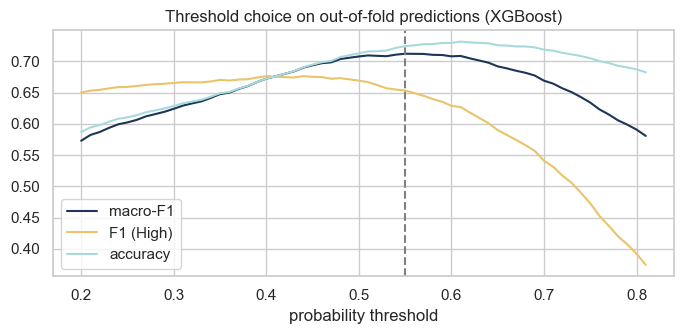

In [16]:
oof = cross_val_predict(clone(best_pipe), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
ths = np.round(np.arange(0.20, 0.81, 0.01), 2)
f1s = np.array([f1_score(y_train, oof >= t, average="macro") for t in ths])
THRESHOLD = float(ths[f1s.argmax()])
tuned_cv = {"accuracy": accuracy_score(y_train, oof >= THRESHOLD), "f1": f1_score(y_train, oof >= THRESHOLD),
            "macro_f1": f1_score(y_train, oof >= THRESHOLD, average="macro"),
            "roc_auc": roc_auc_score(y_train, oof)}
print(f"Best threshold (max OOF macro-F1): {THRESHOLD:.2f}  ->  OOF", {k: round(v, 3) for k, v in tuned_cv.items()})
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ths, f1s, c="#1d3557", label="macro-F1")
ax.plot(ths, [f1_score(y_train, oof >= t) for t in ths], c="#e9c46a", label="F1 (High)")
ax.plot(ths, [accuracy_score(y_train, oof >= t) for t in ths], c="#a8dadc", label="accuracy")
ax.axvline(THRESHOLD, ls="--", c="grey"); ax.set_xlabel("probability threshold"); ax.legend()
ax.set_title(f"Threshold choice on out-of-fold predictions ({best_name})")
plt.tight_layout(); save(fig, "threshold"); plt.show()

## 9. Test-set evaluation (held-out 20%, never used for any choice)

In [17]:
def evaluate(pipe, X, y, thr):
    p = pipe.predict_proba(X)[:, 1]; yhat = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat),
            "recall": recall_score(y, yhat), "f1": f1_score(y, yhat), "macro_f1": f1_score(y, yhat, average="macro"),
            "roc_auc": roc_auc_score(y, p)}, p, yhat

test_rows = []
for name, s in tuned.items():
    oof_n = cross_val_predict(clone(s.best_estimator_), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    thr_n = float(ths[np.argmax([f1_score(y_train, oof_n >= t, average="macro") for t in ths])])
    m, _, _ = evaluate(s.best_estimator_, X_test, y_test, thr_n)
    test_rows.append({"model": f"{name} (tuned)", "cv_roc_auc": s.best_score_, "threshold": thr_n,
                      **{f"test_{k}": v for k, v in m.items()}})
test_table = pd.DataFrame(test_rows).set_index("model").sort_values("cv_roc_auc", ascending=False)
display(test_table.round(3))

metrics, p_test, yhat_test = evaluate(best_pipe, X_test, y_test, THRESHOLD)
print(f"\n=== {best_name} on test (threshold {THRESHOLD:.2f}) ===")
print({k: round(v, 3) for k, v in metrics.items()})
print(classification_report(y_test, yhat_test, target_names=["Low", "High"], digits=3))

,cv_roc_auc,threshold,test_accuracy,test_precision,test_recall,test_f1,test_macro_f1,test_roc_auc
model,,,,,,,,
XGBoost (tuned),0.803,0.55,0.742,0.670,0.683,0.676,0.731,0.821
Gradient Boosting (tuned),0.803,0.48,0.739,0.688,0.621,0.653,0.722,0.817
LightGBM (tuned),0.801,0.57,0.749,0.694,0.654,0.673,0.735,0.821



=== XGBoost on test (threshold 0.55) ===
{'accuracy': 0.742, 'precision': 0.67, 'recall': 0.683, 'f1': 0.676, 'macro_f1': 0.731, 'roc_auc': 0.821}
              precision    recall  f1-score   support

         Low      0.791     0.781     0.786       899
        High      0.670     0.683     0.676       586

    accuracy                          0.742      1485
   macro avg      0.730     0.732     0.731      1485
weighted avg      0.743     0.742     0.742      1485



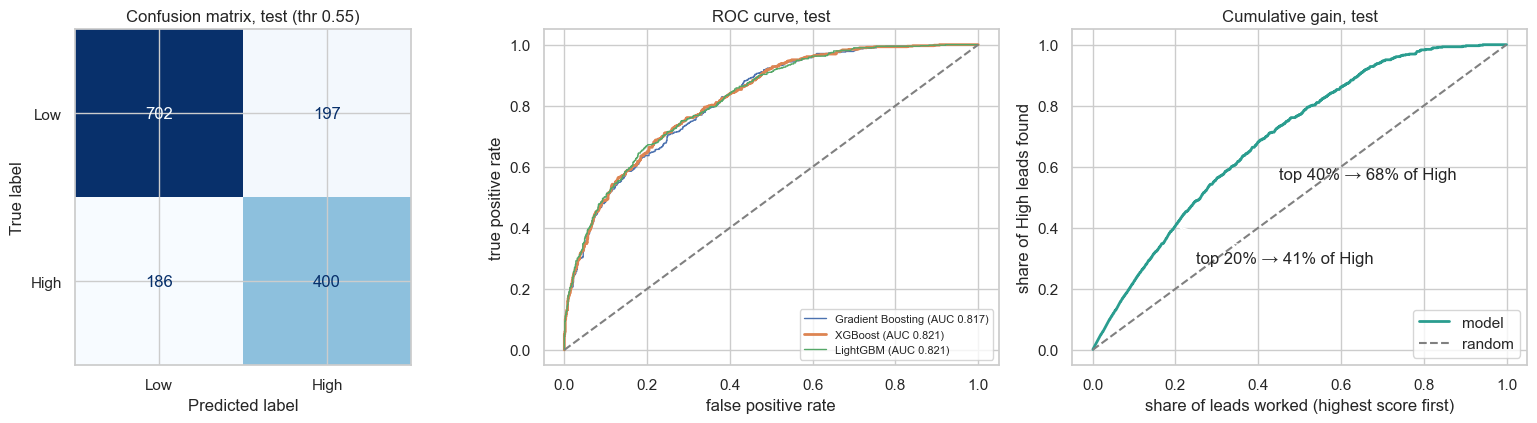

{'top_10pct': 0.2235494880546075,
 'top_20pct': 0.4061433447098976,
 'top_30pct': 0.5614334470989761,
 'top_40pct': 0.6808873720136519,
 'top_50pct': 0.7713310580204779}

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
cm = confusion_matrix(y_test, yhat_test)
ConfusionMatrixDisplay(cm, display_labels=["Low", "High"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Confusion matrix, test (thr {THRESHOLD:.2f})")
for name, s in tuned.items():
    pp = s.best_estimator_.predict_proba(X_test)[:, 1]; fpr, tpr, _ = roc_curve(y_test, pp)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, pp):.3f})", lw=2 if name == best_name else 1)
ax[1].plot([0, 1], [0, 1], ls="--", c="grey"); ax[1].set_title("ROC curve, test"); ax[1].legend(fontsize=8)
ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate")
# Lift: share of all High leads captured when agents work the top-k% of scored leads
order = np.argsort(-p_test); captured = np.cumsum(y_test.values[order]) / y_test.sum()
share = np.arange(1, len(order) + 1) / len(order)
ax[2].plot(share, captured, c=HIGH_C, lw=2, label="model"); ax[2].plot([0, 1], [0, 1], ls="--", c="grey", label="random")
for k in (0.2, 0.4):
    ax[2].annotate(f"top {k:.0%} → {captured[int(k*len(order))-1]:.0%} of High", (k, captured[int(k*len(order))-1]),
                   xytext=(k + 0.05, captured[int(k*len(order))-1] - 0.12), arrowprops=dict(arrowstyle="->"))
ax[2].set_title("Cumulative gain, test"); ax[2].set_xlabel("share of leads worked (highest score first)")
ax[2].set_ylabel("share of High leads found"); ax[2].legend(loc="lower right")
plt.tight_layout(); save(fig, "test_evaluation"); plt.show()
gain = {f"top_{int(k*100)}pct": float(captured[int(k * len(order)) - 1]) for k in (0.1, 0.2, 0.3, 0.4, 0.5)}
gain

## 10. Feature importance

**Permutation importance** on the test set, measured on the *original* lead fields: each field is shuffled and the
drop in ROC-AUC is recorded. This is model-agnostic, and FicZon can read it directly as "how much the model relies
on this field".

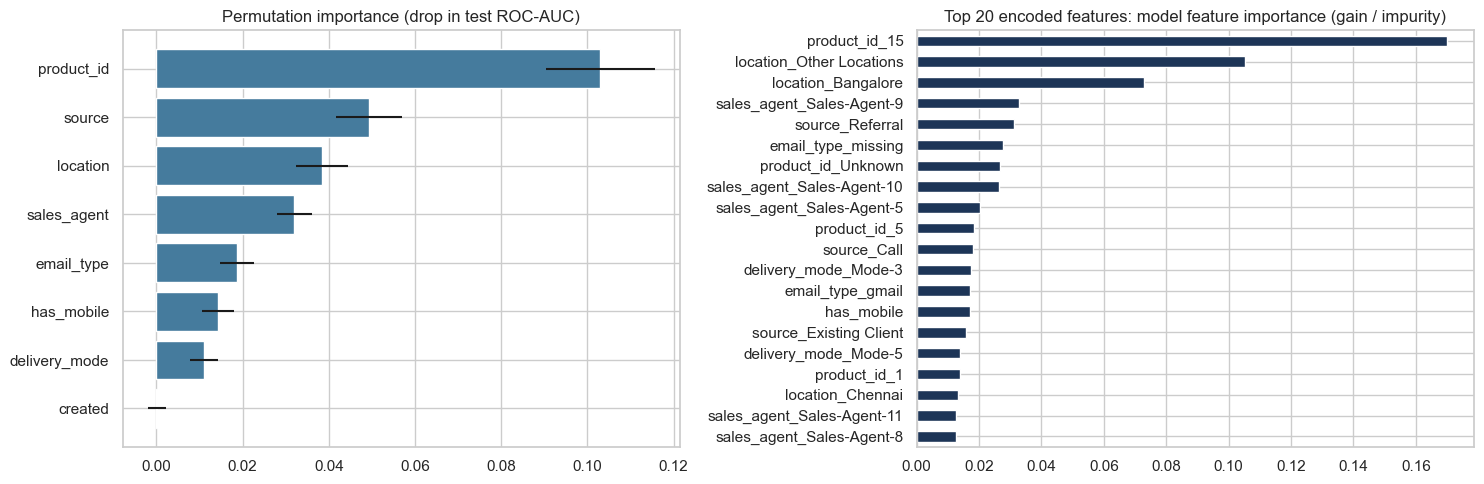

,product_id,source,location,sales_agent,email_type,has_mobile,delivery_mode,created
importance,0.1030,0.0492,0.0384,0.0320,0.0187,0.0142,0.0110,0.0001
std,0.0126,0.0076,0.0060,0.0041,0.0039,0.0037,0.0032,0.0021


In [19]:
pi = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=SEED, n_jobs=-1)
perm = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns)
perm = perm.sort_values("importance")
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].barh(perm.index, perm["importance"], xerr=perm["std"], color="#457b9d")
ax[0].set_title("Permutation importance (drop in test ROC-AUC)")
model = best_pipe.named_steps["model"]; names = best_pipe.named_steps["pre"].get_feature_names_out()
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=names)
    lab = "model feature importance (gain / impurity)"
else:
    imp = pd.Series(np.abs(model.coef_[0]), index=names); lab = "|coefficient|"
imp.sort_values().tail(20).plot.barh(ax=ax[1], color="#1d3557"); ax[1].set_title(f"Top 20 encoded features: {lab}")
plt.tight_layout(); save(fig, "feature_importance"); plt.show()
perm.sort_values("importance", ascending=False).round(4).T

## 11. Robustness check: time-based hold-out

In production the model scores *future* leads. To check this, the best configuration is retrained on leads created
before **1 Oct 2018** and tested on October–November leads. This is harsher than a random split: the latest leads
include many statuses that are still open and a higher High share.

In [20]:
cut = pd.Timestamp("2018-10-01")
early, late = leads["created"] < cut, leads["created"] >= cut
pipe_t = clone(best_pipe).fit(X_all[early], y_all[early])
m_time, _, _ = evaluate(pipe_t, X_all[late], y_all[late], THRESHOLD)
print(f"train {early.sum()} leads (High {y_all[early].mean():.1%}) -> test {late.sum()} leads (High {y_all[late].mean():.1%})")
print({k: round(v, 3) for k, v in m_time.items()})

train 6039 leads (High 37.3%) -> test 1383 leads (High 48.9%)
{'accuracy': 0.727, 'precision': 0.719, 'recall': 0.726, 'f1': 0.723, 'macro_f1': 0.727, 'roc_auc': 0.813}


## 12. Save the model

The saved file is a **single sklearn pipeline**: feature engineering → one-hot encoding → model. It is refit on
**all** 7,422 leads with the tuned settings. The metadata JSON holds the threshold, metrics and allowed input values
for the API/UI. **No raw data is saved next to the model.**

In [21]:
final_pipe = clone(best_pipe).fit(X_all, y_all)
joblib.dump(final_pipe, MODELS / "lead_quality_pipeline.joblib", compress=3)

model_lib = type(final_pipe.named_steps["model"]).__module__.split(".")[0]
import importlib.metadata as md_
lib_versions = {p: md_.version(p) for p in ["scikit-learn", "pandas", "numpy", "joblib"] +
                ({"xgboost": ["xgboost"], "lightgbm": ["lightgbm"]}.get(model_lib, []))}
top_products = leads["product_id"].value_counts()
meta = {
    "model_name": f"{best_name} (tuned) pipeline",
    "model_library": model_lib, "library_versions": lib_versions,
    "trained_on_leads": int(len(leads)), "train_period": [str(leads["created"].min()), str(leads["created"].max())],
    "target": {"1": "High potential", "0": "Low potential", "high_statuses": HIGH_STATUSES, "low_statuses": LOW_STATUSES},
    "threshold": THRESHOLD,
    "best_params": {k.replace("model__", ""): (v if not isinstance(v, (np.integer, np.floating)) else v.item())
                    for k, v in tuned[best_name].best_params_.items()},
    "cv_metrics": {k: float(v) for k, v in tuned_cv.items()},
    "test_metrics": {k: float(v) for k, v in metrics.items()},
    "test_confusion_matrix": {"labels": ["Low", "High"], "matrix": cm.tolist()},
    "time_holdout_metrics": {k: float(v) for k, v in m_time.items()},
    "cumulative_gain_test": gain,
    "permutation_importance": perm["importance"].sort_values(ascending=False).round(4).to_dict(),
    "input_fields": LEAD_FIELDS,
    "choices": {
        "product_id": sorted(top_products.index.tolist(), key=lambda v: (v == "Unknown", int(v) if v.isdigit() else 0)),
        "source": SOURCE_CHOICES, "sales_agent": sorted(leads["sales_agent"].unique().tolist(),
                                                        key=lambda v: (v == "Unknown", int(v.split("-")[-1]) if v[-1].isdigit() else 0)),
        "location": LOCATION_CHOICES, "delivery_mode": DELIVERY_CHOICES, "email_type": EMAIL_CHOICES},
}
(MODELS / "model_metadata.json").write_text(json.dumps(meta, indent=2))

comparison = cv_results.drop(columns=["fit_s"]).rename(columns=lambda c: f"cv_{c}")
comparison = comparison.join(test_table.rename(index=lambda s: s.replace(" (tuned)", ""))[
    ["cv_roc_auc", "threshold", "test_accuracy", "test_f1", "test_macro_f1", "test_roc_auc"]].rename(columns={"cv_roc_auc": "tuned_cv_roc_auc"}))
comparison.round(4).to_csv(MODELS / "model_comparison.csv")
print("Saved:", [p.name for p in MODELS.iterdir()])
print("Model size: %.1f KB" % ((MODELS / "lead_quality_pipeline.joblib").stat().st_size / 1024))

# Sanity check: reload and score one hand-written lead
reloaded = joblib.load(MODELS / "lead_quality_pipeline.joblib")
demo = pd.DataFrame([{"created": "2018-11-10 11:30", "product_id": "27", "source": "Referral",
                      "sales_agent": "Sales-Agent-9", "location": "Bangalore", "delivery_mode": "Mode-4",
                      "has_mobile": 1, "email_type": "gmail"}])
print("demo lead P(High) = %.3f" % reloaded.predict_proba(demo)[0, 1])
comparison.round(3)

Saved: ['lead_quality_pipeline.joblib', 'model_comparison.csv', 'model_metadata.json']
Model size: 53.5 KB
demo lead P(High) = 0.968


,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_roc_auc_std,tuned_cv_roc_auc,threshold,test_accuracy,test_f1,test_macro_f1,test_roc_auc
model,,,,,,,,,,,,
Gradient Boosting,0.729,0.687,0.578,0.627,0.802,0.011,0.803,0.48,0.739,0.653,0.722,0.817
XGBoost,0.712,0.616,0.720,0.664,0.800,0.013,0.803,0.55,0.742,0.676,0.731,0.821
LightGBM,0.711,0.615,0.716,0.662,0.800,0.012,0.801,0.57,0.749,0.673,0.735,0.821
Logistic Regression,0.708,0.606,0.742,0.667,0.797,0.012,NaN,NaN,NaN,NaN,NaN,NaN
Extra Trees,0.706,0.610,0.712,0.657,0.793,0.010,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,0.711,0.624,0.673,0.648,0.792,0.010,NaN,NaN,NaN,NaN,NaN,NaN
Decision Tree,0.690,0.608,0.629,0.615,0.761,0.013,NaN,NaN,NaN,NaN,NaN,NaN
KNN (k=25),0.700,0.644,0.541,0.587,0.761,0.013,NaN,NaN,NaN,NaN,NaN,NaN
Dummy (majority),0.605,0.000,0.000,0.000,0.500,0.000,NaN,NaN,NaN,NaN,NaN,NaN


## 13. Findings, recommendations and challenges

The numbers below are filled in from the run above (see `models/model_metadata.json`).

In [22]:
mt = meta["test_metrics"]
print(f"Selected model : {best_name} (tuned), threshold {THRESHOLD:.2f}")
print(f"5-fold CV (OOF): accuracy {tuned_cv['accuracy']:.3f} | F1 {tuned_cv['f1']:.3f} | ROC-AUC {tuned_cv['roc_auc']:.3f}")
print(f"Test           : accuracy {mt['accuracy']:.3f} | F1(High) {mt['f1']:.3f} | ROC-AUC {mt['roc_auc']:.3f} | "
      f"precision {mt['precision']:.3f} | recall {mt['recall']:.3f}")
print(f"Time hold-out  : accuracy {m_time['accuracy']:.3f} | F1 {m_time['f1']:.3f} | ROC-AUC {m_time['roc_auc']:.3f}")
print(f"Gain           : working the top 20% of scored leads finds {gain['top_20pct']:.0%} of High leads, "
      f"top 40% finds {gain['top_40pct']:.0%}")
print("Top fields     :", ", ".join(list(meta["permutation_importance"])[:4]))

Selected model : XGBoost (tuned), threshold 0.55
5-fold CV (OOF): accuracy 0.724 | F1 0.653 | ROC-AUC 0.802
Test           : accuracy 0.742 | F1(High) 0.676 | ROC-AUC 0.821 | precision 0.670 | recall 0.683
Time hold-out  : accuracy 0.727 | F1 0.723 | ROC-AUC 0.813
Gain           : working the top 20% of scored leads finds 41% of High leads, top 40% finds 68%
Top fields     : product_id, source, location, sales_agent


**Findings**
1. Lead quality can be predicted from information known when the lead arrives, with ROC-AUC around 0.80. That is a
   clear, useful ranking, but not a perfect classifier. The rest depends on the conversation itself, which the data
   does not capture.
2. Tree-boosting and linear models end up close together. Most of the signal is in a few categorical fields
   (delivery mode, agent, product, contact quality), and there are few complex interactions to find.
3. **Contact quality is a cheap, strong signal**: leads with no usable e-mail (`#VALUE!`) are mostly Low.
4. Ranking leads by score concentrates High leads at the top (cumulative-gain chart), which is what a sales team
   needs to prioritise its day.

**Recommendations for FicZon**
- Use the score to **order the lead queue**: call High leads first, and send low-scoring leads to nurture e-mails.
- Fix the **web form / CRM export** that writes `#VALUE!` into e-mails, and make mobile number mandatory.
- Review **product 15**, the **"Other Locations"** bucket, the **US website** and **Delivery Mode 5**. They bring
  many leads but few good ones (lead-gen spend there could be cut or re-targeted).
- Grow **referral and existing-client** programmes: almost 9 in 10 of those leads are High potential.
- Share agent-level conversion rates for coaching (Agent-9's practices vs Agent-5's).
- Retrain monthly. Close out `Open` leads before retraining so the most recent month is not biased.

**Challenges faced**
- *Masked PII and Excel errors* (`#VALUE!`, short masked phone numbers) → turned into contact-quality flags.
- *Messy categories* (25 sources, near-duplicate names, rare products, single-lead locations) → business grouping
  plus the encoder's infrequent bucket, which also makes the API robust to new values.
- *Inconsistent labels* (`CONVERTED` / `converted`) and an ambiguous `Open` status → documented mapping.
- *Moderate imbalance (60/40)* → class weights compared against SMOTE / undersampling inside CV; threshold tuned on
  out-of-fold macro-F1 (F1 for High alone over-flags leads).
- *Time drift* (High share rises in recent months) → month left out of the features, plus a time-based hold-out check.
- *Confidential dataset* → no raw rows printed, raw CSV excluded from git and from the deployed image.